<a href="https://colab.research.google.com/github/cdelriomancilla-IACC/IACC-Tarea_Semana_8/blob/main/Pregunta_1_Tarea_Semana_8_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

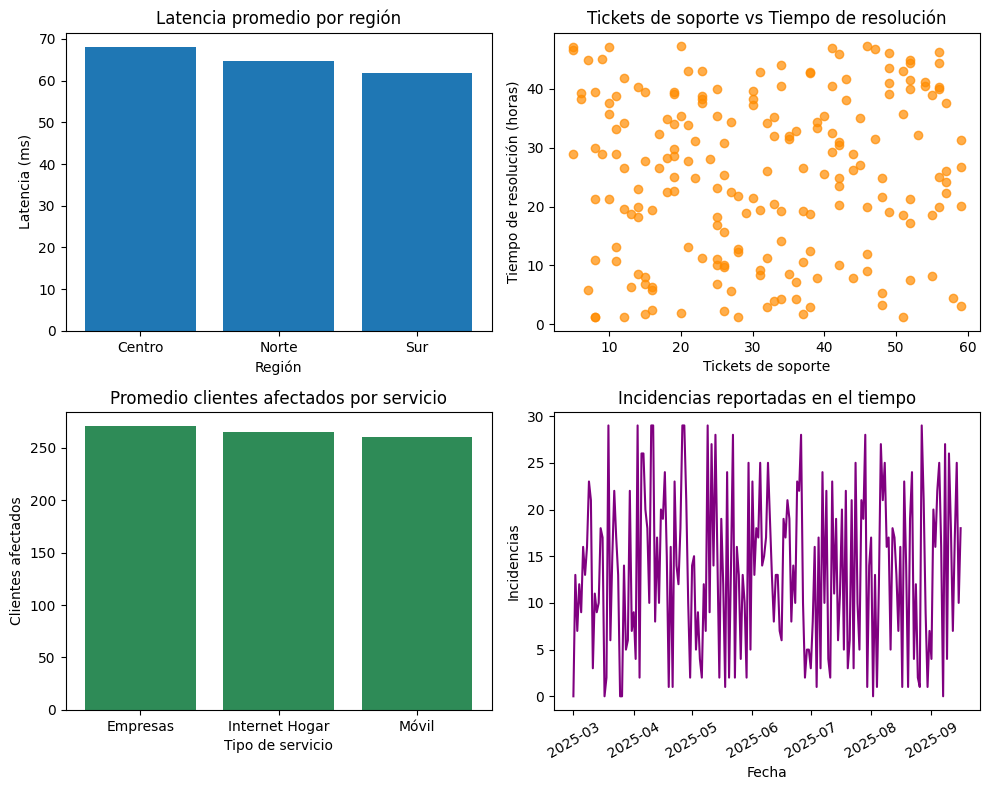

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Carga del conjunto de datos oficial
data = pd.read_excel('dataset_set_D_telecomunicaciones.xlsx')

# 2. Generación de archivos de salida para áreas funcionales
# Salida para Área de Soporte Técnico
soporte = data[[
    'fecha_registro',
    'region',
    'tipo_servicio',
    'incidencias_reportadas',
    'tickets_soporte',
    'tiempo_resolucion_hr',
]]
soporte.to_csv('salida_soporte_tecnico.csv', index=False)

# Salida para Área de Experiencia de Clientes
experiencia = data[[
    'fecha_registro',
    'tipo_servicio',
    'clientes_afectados',
    'latencia_ms',
    'cumplimiento_sla',
]]
experiencia.to_csv('salida_experiencia_clientes.csv', index=False)

# 3. Construcción del Dashboard Exploratorio
plt.figure(figsize=(10, 8))

# Subplot 1: Latencia promedio por región
latencia_region = data.groupby('region')['latencia_ms'].mean()
plt.subplot(2, 2,1)
plt.bar(latencia_region.index, latencia_region.values)
plt.title('Latencia promedio por región')
plt.xlabel('Región')
plt.ylabel('Latencia (ms)')

# Subplot 2: Tickets de soporte vs Tiempo de resolución
plt.subplot(2, 2,2)
plt.scatter(
    data['tickets_soporte'],
    data['tiempo_resolucion_hr'],
    color='darkorange',
    alpha=0.7,
)
plt.title('Tickets de soporte vs Tiempo de resolución')
plt.xlabel('Tickets de soporte')
plt.ylabel('Tiempo de resolución (horas)')

# Subplot 3: Clientes afectados promedio por servicio
clientes_servicio = data.groupby('tipo_servicio')['clientes_afectados'].mean()
plt.subplot(2, 2,3)
plt.bar(clientes_servicio.index, clientes_servicio.values, color='seagreen')
plt.title('Promedio clientes afectados por servicio')
plt.xlabel('Tipo de servicio')
plt.ylabel('Clientes afectados')

# Subplot 4: Evolución temporal de incidencias
data_ordenada = data.sort_values('fecha_registro')
plt.subplot(2, 2,4)
plt.plot(
    data_ordenada['fecha_registro'],
    data_ordenada['incidencias_reportadas'],
    color='purple',
)
plt.title('Incidencias reportadas en el tiempo')
plt.xlabel('Fecha')
plt.ylabel('Incidencias')
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('dashboard_redconecta.png')
plt.show()